<a href="https://colab.research.google.com/github/Bonesha-5/Group4_Formative3_Assignment/blob/main/EM_algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import matplotlib.pyplot as plt

column_types = [
    ("rownames", int),
    ("family", "U10"),
    ("father", float),
    ("mother", float),
    ("midparentHeight", float),
    ("children", int),
    ("childNum", int),
    ("gender", "U10"),
    ("childHeight", float),
]

# Load the dataset
data = np.genfromtxt(
    "GaltonFamilies.csv",
    delimiter=",",
    skip_header=1,
    dtype=column_types,
    encoding="utf-8"
)

# Display the first five rows
print(data[:5])

# Extract one mother per family, and all children
_, unique_indices = np.unique(data["family"], return_index=True)

mothers = data["mother"][unique_indices]
children = data["childHeight"]

# Combine the heights without labels
heights = np.concatenate((mothers, children))

print("Number of mothers:", len(mothers))
print("Number of children:", len(children))
print("Total observations:", len(heights))
print("Overall mean:", np.mean(heights))

[(1, '001', 78.5, 67. , 75.43, 4, 1, 'male', 73.2)
 (2, '001', 78.5, 67. , 75.43, 4, 2, 'female', 69.2)
 (3, '001', 78.5, 67. , 75.43, 4, 3, 'female', 69. )
 (4, '001', 78.5, 67. , 75.43, 4, 4, 'female', 69. )
 (5, '002', 75.5, 66.5, 73.66, 4, 1, 'male', 73.5)]
Number of mothers: 205
Number of children: 934
Total observations: 1139
Overall mean: 66.25206321334504


In [3]:

# Extract unique mothers using family IDs
_, indices = np.unique(data["family"], return_index=True)

mothers = data["mother"][indices]

# Extract children's heights
children = data["childHeight"]

# Check the number of observations
print("Number of mothers:", len(mothers))
print("Number of children:", len(children))


Number of mothers: 205
Number of children: 934


In [4]:
# Combine mothers' and children's heights
heights = np.concatenate((mothers, children))

print("Total observations:", len(heights))
print("Overall mean:", np.mean(heights))
print("Overall variance:", np.var(heights))
print("Minimum height:", np.min(heights))
print("Maximum height:", np.max(heights))


Total observations: 1139
Overall mean: 66.25206321334504
Overall variance: 12.580160361236732
Minimum height: 56.0
Maximum height: 79.0


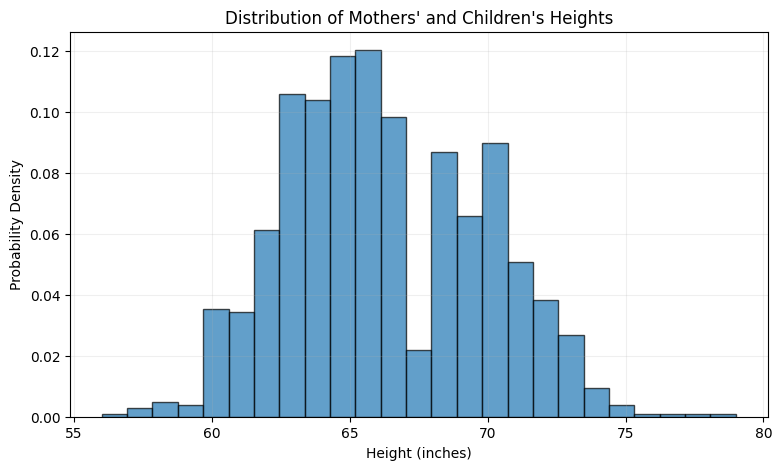

In [5]:
plt.figure(figsize=(9, 5))

plt.hist(
    heights,
    bins=25,
    density=True,
    edgecolor="black",
    alpha=0.7
)

plt.xlabel("Height (inches)")
plt.ylabel("Probability Density")
plt.title("Distribution of Mothers' and Children's Heights")
plt.grid(alpha=0.2)

plt.show()


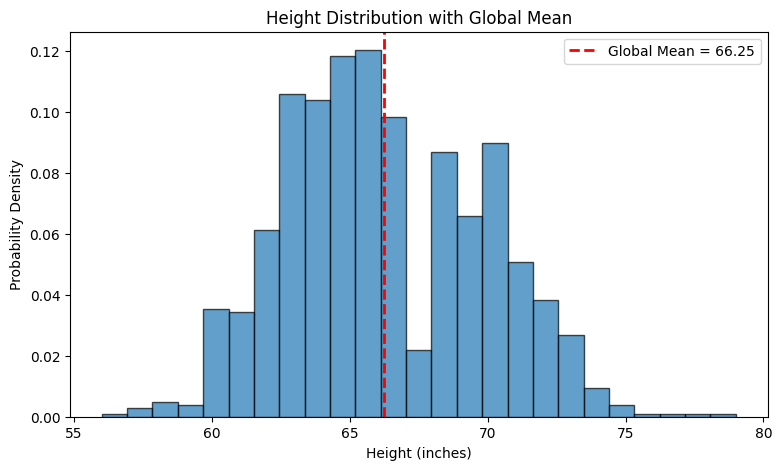

In [6]:
global_mean = np.mean(heights)

plt.figure(figsize=(9, 5))

plt.hist(
    heights,
    bins=25,
    density=True,
    edgecolor="black",
    alpha=0.7
)

plt.axvline(
    global_mean,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Global Mean = {global_mean:.2f}"
)

plt.xlabel("Height (inches)")
plt.ylabel("Probability Density")
plt.title("Height Distribution with Global Mean")
plt.legend()
plt.show()


In [7]:
# Initialize the means
mean1 = np.percentile(heights, 60)
mean2 = np.percentile(heights, 70)

# Initialize the variances
var1 = np.var(heights)
var2 = np.var(heights)

# Initialize the mixing weights
pi1 = 0.5
pi2 = 0.5

# Display the initial parameters
print("Initial mean 1:", mean1)
print("Initial mean 2:", mean2)
print("Initial variance 1:", var1)
print("Initial variance 2:", var2)
print("Initial pi1:", pi1)
print("Initial pi2:", pi2)


Initial mean 1: 67.0
Initial mean 2: 68.0
Initial variance 1: 12.580160361236732
Initial variance 2: 12.580160361236732
Initial pi1: 0.5
Initial pi2: 0.5



Gaussian Probability Density Function

In [8]:
def gaussian_pdf(x, mean, variance):
    coefficient = 1 / np.sqrt(2 * np.pi * variance)
    exponent = -((x - mean) ** 2) / (2 * variance)
    return coefficient * np.exp(exponent)

Calculating E-steps

In [9]:
def e_step(heights, mean1, mean2, var1, var2, pi1, pi2):
    # Calculate weighted Gaussian densities
    p1 = pi1 * gaussian_pdf(heights, mean1, var1)
    p2 = pi2 * gaussian_pdf(heights, mean2, var2)

    # Calculate total probability density
    total = p1 + p2

    # Calculate responsibilities
    gamma1 = p1 / total
    gamma2 = p2 / total

    return gamma1, gamma2

Testing the E-step

In [10]:
gamma1, gamma2 = e_step(
    heights, mean1, mean2, var1, var2, pi1, pi2
)

print("Gamma 1:", gamma1[:5])
print("Gamma 2:", gamma2[:5])
print("Responsibilities sum to 1:",
      np.allclose(gamma1 + gamma2, 1))

Gamma 1: [0.50993497 0.5198621  0.56910876 0.56910876 0.67159595]
Gamma 2: [0.49006503 0.4801379  0.43089124 0.43089124 0.32840405]
Responsibilities sum to 1: True


Calculate how well each height fits each curve using the starting guess.

In [11]:
p1 = pi1 * gaussian_pdf(heights, mean1, var1)
p2 = pi2 * gaussian_pdf(heights, mean2, var2)

total = p1 + p2

print("Gaussian 1:", p1[:5])
print("Gaussian 2:", p2[:5])

Gaussian 1: [0.05623892 0.05568288 0.03932667 0.03932667 0.00318364]
Gaussian 2: [0.05404754 0.05142799 0.02977554 0.02977554 0.00155677]


Measure how well the starting guess fits the data with the log-likelihood.

In [12]:
log_likelihood = np.sum(np.log(total))

print("Initial Log-Likelihood:", log_likelihood)

Initial Log-Likelihood: -3127.425237320224


Create a list to store every iteration and save the starting values as iteration 0.

In [13]:
history = []

history.append([
    0,
    mean1,
    mean2,
    var1,
    var2,
    pi1,
    pi2,
    log_likelihood
])

print("Iteration 0:", history[0])

Iteration 0: [0, np.float64(67.0), np.float64(68.0), np.float64(12.580160361236732), np.float64(12.580160361236732), 0.5, 0.5, np.float64(-3127.425237320224)]


M-step: update the two means as weighted averages using the responsibilities.

In [14]:
# Update the means
new_mean1 = np.sum(gamma1 * heights) / np.sum(gamma1)
new_mean2 = np.sum(gamma2 * heights) / np.sum(gamma2)

print("Updated mean 1:", new_mean1)
print("Updated mean 2:", new_mean2)

Updated mean 1: 65.7836924553692
Updated mean 2: 66.76849318203077


M-step: update the two variances around the new means.

In [15]:
# Update the variances using the new means
new_var1 = np.sum(gamma1 * (heights - new_mean1)**2) / np.sum(gamma1)
new_var2 = np.sum(gamma2 * (heights - new_mean2)**2) / np.sum(gamma2)

print("Updated variance 1:", new_var1)
print("Updated variance 2:", new_var2)

Updated variance 1: 11.986723187390842
Updated variance 2: 12.72590911877733


M-step: update the mixing weights, the fraction of people in each group.

In [16]:
# Update mixing weights
new_pi1 = np.sum(gamma1) / len(heights)
new_pi2 = np.sum(gamma2) / len(heights)

print("Updated pi1:", new_pi1)
print("Updated pi2:", new_pi2)
print("Sum of weights:", new_pi1 + new_pi2)

Updated pi1: 0.5244004748416657
Updated pi2: 0.47559952515833426
Sum of weights: 1.0


Replace the old parameters with the updated ones.

In [17]:
# Replace old parameters with updated values
mean1 = new_mean1
mean2 = new_mean2

var1 = new_var1
var2 = new_var2

pi1 = new_pi1
pi2 = new_pi2

Recalculate the log-likelihood and save the results as iteration 1.

In [18]:
# Calculate densities using updated parameters
p1 = pi1 * gaussian_pdf(heights, mean1, var1)
p2 = pi2 * gaussian_pdf(heights, mean2, var2)

total = p1 + p2

# Log-likelihood after iteration 1
log_likelihood = np.sum(np.log(total))

# Save iteration 1
history.append([
    1,
    mean1,
    mean2,
    var1,
    var2,
    pi1,
    pi2,
    log_likelihood
])

print("Iteration 1:", history[1])

Iteration 1: [1, np.float64(65.7836924553692), np.float64(66.76849318203077), np.float64(11.986723187390842), np.float64(12.72590911877733), np.float64(0.5244004748416657), np.float64(0.47559952515833426), np.float64(-3057.739007228647)]


E-step for iteration 2: recalculate the responsibilities with the improved curves.

In [19]:
# E-step: Iteration 2

p1 = pi1 * gaussian_pdf(heights, mean1, var1)
p2 = pi2 * gaussian_pdf(heights, mean2, var2)

total = p1 + p2

gamma1 = p1 / total
gamma2 = p2 / total

print("Gaussian 1 responsibilities:", gamma1[:5])
print("Gaussian 2 responsibilities:", gamma2[:5])

Gaussian 1 responsibilities: [0.51699228 0.52723036 0.57347116 0.57347116 0.64584312]
Gaussian 2 responsibilities: [0.48300772 0.47276964 0.42652884 0.42652884 0.35415688]


M-step for iteration 2: update the means, variances and mixing weights again.

In [20]:
# M-step: Iteration 2
new_mean1 = np.sum(gamma1 * heights) / np.sum(gamma1)
new_mean2 = np.sum(gamma2 * heights) / np.sum(gamma2)

new_var1 = np.sum(gamma1 * (heights - new_mean1)**2) / np.sum(gamma1)
new_var2 = np.sum(gamma2 * (heights - new_mean2)**2) / np.sum(gamma2)

new_pi1 = np.sum(gamma1) / len(heights)
new_pi2 = np.sum(gamma2) / len(heights)

# Update parameters
mean1, mean2 = new_mean1, new_mean2
var1, var2 = new_var1, new_var2
pi1, pi2 = new_pi1, new_pi2

print("Updated means:", mean1, mean2)
print("Updated variances:", var1, var2)
print("Updated mixing weights:", pi1, pi2)

Updated means: 65.77234176043814 66.78106880588302
Updated variances: 11.708167606965766 13.008114963056963
Updated mixing weights: 0.5244288778880439 0.4755711221119561


Recalculate the log-likelihood and save the results as iteration 2.

In [21]:
# Recalculate densities with updated parameters
p1 = pi1 * gaussian_pdf(heights, mean1, var1)
p2 = pi2 * gaussian_pdf(heights, mean2, var2)

total = p1 + p2

log_likelihood = np.sum(np.log(total))

# Save iteration 2
history.append([
    2,
    mean1,
    mean2,
    var1,
    var2,
    pi1,
    pi2,
    log_likelihood
])

print("Iteration 2:", history[2])

Iteration 2: [2, np.float64(65.77234176043814), np.float64(66.78106880588302), np.float64(11.708167606965766), np.float64(13.008114963056963), np.float64(0.5244288778880439), np.float64(0.4755711221119561), np.float64(-3057.459782218908)]


Repeat the E-step and M-step until the log-likelihood stops changing (convergence)

In [22]:
# Convergence settings
max_iterations = 1000
tolerance = 1e-6

previous_log_likelihood = log_likelihood
converged = False

for iteration in range(3, max_iterations + 1):

    # E-step
    p1 = pi1 * gaussian_pdf(heights, mean1, var1)
    p2 = pi2 * gaussian_pdf(heights, mean2, var2)

    total = p1 + p2

    gamma1 = p1 / total
    gamma2 = p2 / total

    new_mean1 = np.sum(gamma1 * heights) / np.sum(gamma1)
    new_mean2 = np.sum(gamma2 * heights) / np.sum(gamma2)

    new_var1 = np.sum(gamma1 * (heights - new_mean1)**2) / np.sum(gamma1)
    new_var2 = np.sum(gamma2 * (heights - new_mean2)**2) / np.sum(gamma2)

    new_pi1 = np.mean(gamma1)
    new_pi2 = np.mean(gamma2)

    mean1, mean2 = new_mean1, new_mean2
    var1, var2 = new_var1, new_var2
    pi1, pi2 = new_pi1, new_pi2

    p1 = pi1 * gaussian_pdf(heights, mean1, var1)
    p2 = pi2 * gaussian_pdf(heights, mean2, var2)

    total = p1 + p2

    log_likelihood = np.sum(np.log(total))

    # Save iteration results
    history.append([
        iteration,
        mean1,
        mean2,
        var1,
        var2,
        pi1,
        pi2,
        log_likelihood
    ])

    change = abs(log_likelihood - previous_log_likelihood)

    if change < tolerance:
        converged = True
        print("Converged at iteration:", iteration)
        break

    previous_log_likelihood = log_likelihood

if not converged:
    print("Maximum iterations reached without convergence")

print("Final log-likelihood:", log_likelihood)

Converged at iteration: 428
Final log-likelihood: -3035.7483752359867


## Initialization and first two iterations

In [23]:
print(f"{'Iter':<6}{'mu1':>8}{'mu2':>8}{'var1':>8}{'var2':>8}{'pi1':>8}{'pi2':>8}{'Log-Lik':>12}")
print("-" * 66)
for row in history[:3]:
    it, m1, m2, v1, v2, w1, w2, ll = row
    print(f"{it:<6}{m1:>8.2f}{m2:>8.2f}{v1:>8.2f}{v2:>8.2f}{w1:>8.3f}{w2:>8.3f}{ll:>12.2f}")

Iter       mu1     mu2    var1    var2     pi1     pi2     Log-Lik
------------------------------------------------------------------
0        67.00   68.00   12.58   12.58   0.500   0.500    -3127.43
1        65.78   66.77   11.99   12.73   0.524   0.476    -3057.74
2        65.77   66.78   11.71   13.01   0.524   0.476    -3057.46


## Classifying a test height

In [24]:
def classify(height, unit="in"):
    x = height / 2.54 if unit == "cm" else height
    g1, g2 = e_step(np.array([x]), mean1, mean2, var1, var2, pi1, pi2)
    print(f"Height: {height} {unit} = {x:.2f} in")
    print(f"P(Group 1, shorter, mean {mean1:.1f} in) = {g1[0]:.4f}")
    print(f"P(Group 2, taller,  mean {mean2:.1f} in) = {g2[0]:.4f}")
    return g1[0], g2[0]


classify(66)
print()
classify(170, unit="cm")

Height: 66 in = 66.00 in
P(Group 1, shorter, mean 64.3 in) = 0.8353
P(Group 2, taller,  mean 69.8 in) = 0.1647

Height: 170 cm = 66.93 in
P(Group 1, shorter, mean 64.3 in) = 0.6711
P(Group 2, taller,  mean 69.8 in) = 0.3289


(np.float64(0.67106604878666), np.float64(0.32893395121334))

## Should we split at the global mean? (check with the hidden labels)

We compare the naive split with the truth. The labels are used **only** for this check, never by EM.

In [25]:
true_labels = np.concatenate((np.zeros(len(mothers)), np.ones(len(children))))   # 0 = mother, 1 = child
global_mean = np.mean(heights)

below = heights[heights < global_mean]
above = heights[heights >= global_mean]
naive_pred = (heights >= global_mean).astype(int)

print(f"Global mean: {global_mean:.2f} in")
print(f"Pile means from the split: {below.mean():.2f} and {above.mean():.2f}")
print(f"True means: mothers {mothers.mean():.2f}, children {children.mean():.2f}")
print(f"Naive split accuracy (below = mother): {np.mean(naive_pred == true_labels):.1%}")
print(f"Children wrongly called 'mother': {np.mean(naive_pred[true_labels == 1] == 0):.1%}")

Global mean: 66.25 in
Pile means from the split: 63.58 and 69.47
True means: mothers 64.00, children 66.75
Naive split accuracy (below = mother): 57.6%
Children wrongly called 'mother': 48.2%


## The fitted mixture on top of the data

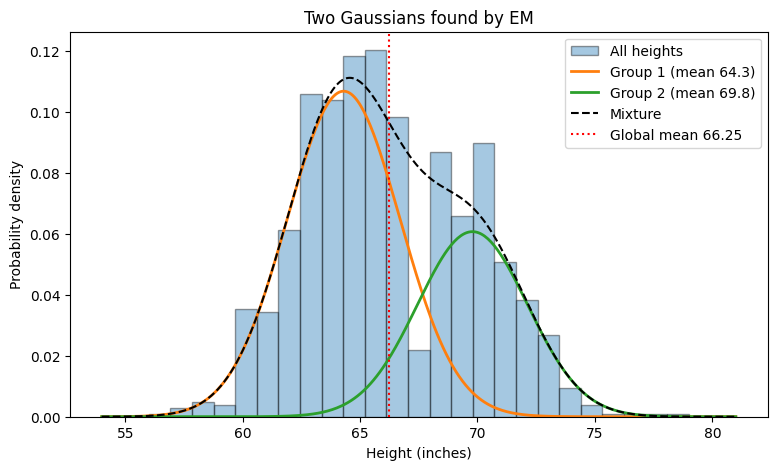

In [26]:
xs = np.linspace(heights.min() - 2, heights.max() + 2, 400)
curve1 = pi1 * gaussian_pdf(xs, mean1, var1)
curve2 = pi2 * gaussian_pdf(xs, mean2, var2)

plt.figure(figsize=(9, 5))
plt.hist(heights, bins=25, density=True, edgecolor="black", alpha=0.4, label="All heights")
plt.plot(xs, curve1, linewidth=2, label=f"Group 1 (mean {mean1:.1f})")
plt.plot(xs, curve2, linewidth=2, label=f"Group 2 (mean {mean2:.1f})")
plt.plot(xs, curve1 + curve2, "k--", linewidth=1.5, label="Mixture")
plt.axvline(global_mean, color="red", linestyle=":", label=f"Global mean {global_mean:.2f}")
plt.xlabel("Height (inches)")
plt.ylabel("Probability density")
plt.title("Two Gaussians found by EM")
plt.legend()
plt.show()

## Loglikelihood over iterations

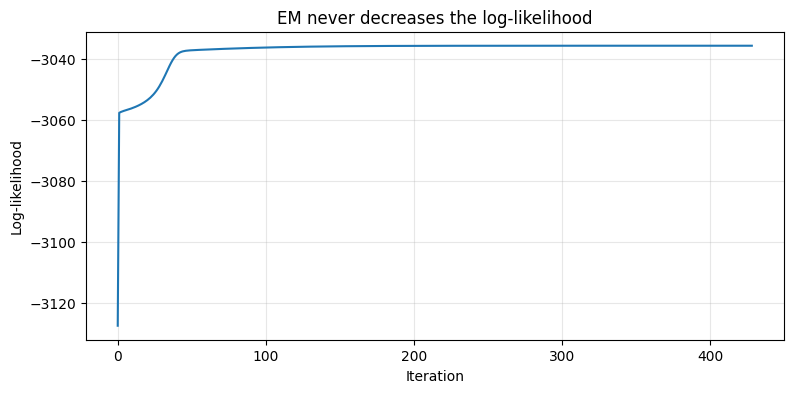

Log-likelihood ever decreased: False


In [27]:
log_liks = [row[7] for row in history]
plt.figure(figsize=(9, 4))
plt.plot(range(len(log_liks)), log_liks)
plt.xlabel("Iteration")
plt.ylabel("Log-likelihood")
plt.title("EM never decreases the log-likelihood")
plt.grid(alpha=0.3)
plt.show()

print("Log-likelihood ever decreased:", any(b < a - 1e-9 for a, b in zip(log_liks, log_liks[1:])))